# Análisis gráfico: **Hidrocarburos**
**Fuente de datos:** CAS SciFinder, organizados en `tabla_hidrocarburos.xlsx` (hojas *Sustancias*, *Reacciones* y *Obtenciones*).

**Criterio de las gráficas:** cada gráfica responde a una relación química. Variables numéricas → dispersión, líneas, doble eje, cajas, histogramas o densidad. Variables categóricas (medio, tipo de reacción, solvente) → barras, dona o burbujas de frecuencia. Referencia: [datavizcatalogue.com/ES](https://datavizcatalogue.com/ES/buscar.html). Colores según [Datawrapper](https://www.datawrapper.de/blog/colors): máximo 7, cada variable conserva su color en todo el cuaderno y el gris se usa para lo secundario.

## 1. Librerías, estilo y carga del archivo

**Qué hace el código.** Antes de analizar se deja listo el entorno:

- **Librerías:** `pandas` para las tablas, `numpy` para los cálculos, `matplotlib` y `seaborn` para las figuras, `scipy.stats` para regresiones y pruebas de correlación, y `plotly` para las dos gráficas interactivas del final.

- **Estilo único:** tipografía con serifa, ejes sin borde arriba ni a la derecha, cuadrícula suave y figuras guardadas a 300 ppp.
- **Colores fijos tomados de la escala viridis:** azul para Reacciones, verde para Obtenciones y un color propio por propiedad y por medio. El gris queda para lo secundario.
- **Datos:** se crea `figuras_hidrocarburos/`. Si se pega en `URL` el enlace del Excel en GitHub, se descarga directamente; si `URL` queda vacía, Colab abre la ventana para subir `tabla_hidrocarburos.xlsx`.

In [ ]:
# Relación que se prepara: ninguna todavía; esta celda carga las herramientas y el estilo común a todas las gráficas.
import os, shutil                      # os crea carpetas; shutil comprime las figuras en un .zip
import urllib.request                  # descarga archivos desde internet (el Excel en GitHub)
import numpy as np                     # numpy: operaciones numéricas (logaritmos, raíces, arreglos)
import pandas as pd                    # pandas: tablas (DataFrames) leídas desde Excel
import matplotlib.pyplot as plt        # matplotlib: motor de dibujo de todas las figuras
import seaborn as sns                  # seaborn: gráficas estadísticas sobre matplotlib
from matplotlib.colors import LinearSegmentedColormap   # para construir escalas de color propias
from scipy import stats                # scipy.stats: regresión lineal, Pearson, Spearman, Mann-Whitney
import plotly.express as px            # plotly: gráficas interactivas (pasar el cursor sobre los puntos)

# try/except: si el cuaderno corre en Colab se usa el botón para subir archivos; si no, se lee el archivo local.
try:
    from google.colab import files     # solo existe dentro de Google Colab
    EN_COLAB = True
except ImportError:                    # fuera de Colab no existe ese módulo y se cae aquí
    EN_COLAB = False

from matplotlib import font_manager    # para revisar qué tipografías están instaladas
sns.set_theme(style='white', font_scale=1.0)          # fondo limpio, sin cuadrícula fuerte
instaladas = {f.name for f in font_manager.fontManager.ttflist}        # nombres de fuentes disponibles
FUENTE = [f for f in ['DejaVu Sans'] if f in instaladas] + ['DejaVu Sans']   # si falta, usa DejaVu Sans
plt.rcParams.update({
    'font.family': FUENTE,                                  # tipografía propia de este proyecto
    'axes.spines.top': False, 'axes.spines.right': False,   # se quitan los bordes que no aportan
    'axes.grid': True, 'grid.color': '#EDEDED', 'grid.linewidth': 0.6,  # cuadrícula suave
    'savefig.dpi': 300, 'figure.dpi': 100,                  # 300 ppp para el informe en LaTeX
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})

# Colores fijos: la misma variable tiene el mismo color en todas las gráficas.
COL_VAR = {'PM': '#440154', 'Pf': '#3B528B', 'Peb': '#21918C', 'ρ': '#5EC962', 'Pv': '#90A4AE', 'μ': '#7B3294', 'Sol': '#2C7FB8'}
COL_CONJ = {'Reacciones': '#3B528B', 'Obtenciones': '#5EC962'}                 # reacciones (sustancia como reactivo) vs. obtenciones (como producto)
COL_MEDIO = {'Ácido': '#440154', 'Básico': '#21918C', 'Neutro': '#B0B7BF', 'Apolar': '#5EC962'}               # medio de reacción
COL_SI = {'cat': '#4D4D4D', 'calor': '#D08C60'}                   # colores para las variables sí/no (catalizador, calor)
GRIS = '#9E9E9E'                       # gris para lo secundario (líneas de referencia, puntos de fondo)
DIV = LinearSegmentedColormap.from_list('div', ['#5B8C6E', '#E4E4E4', '#C08A3E'])   # divergente suave con centro gris claro
SEQ = sns.light_palette('#21918C', as_cmap=True)            # secuencial: claro = bajo, oscuro = alto

CARPETA = 'figuras_hidrocarburos'             # carpeta donde se guardan los PNG
os.makedirs(CARPETA, exist_ok=True)    # exist_ok=True evita error si la carpeta ya existe

# Lectura del Excel desde GitHub: pegar entre las comillas el enlace del archivo en el repositorio.
URL = ''                               # ejemplo: https://github.com/USUARIO/REPOSITORIO/blob/main/datos/tabla_hidrocarburos.xlsx
ARCHIVO = 'tabla_hidrocarburos.xlsx'
if URL:                                # if: si hay enlace, se descarga el Excel desde GitHub
    URL = URL.replace('github.com', 'raw.githubusercontent.com').replace('/blob/', '/')   # enlace directo al archivo
    urllib.request.urlretrieve(URL, ARCHIVO)          # descarga y guarda con el nombre ARCHIVO
elif EN_COLAB and not os.path.exists(ARCHIVO):        # elif: sin enlace, se sube a mano en Colab
    subido = files.upload()            # devuelve un diccionario {nombre: contenido}
    ARCHIVO = [n for n in subido if n.endswith('.xlsx')][0]   # toma el primer .xlsx subido
print('Archivo:', ARCHIVO)

Archivo: tabla_hidrocarburos.xlsx


## 2. Lectura y revisión de los datos
La tabla ya viene organizada desde Excel (sin celdas combinadas, unidades solo en el encabezado; los datos que no existen están escritos como NA (no aplica) y pandas los lee como vacíos (NaN)). Aquí solo se verifica: se quitan espacios, se fuerza el tipo numérico y se cuentan los datos faltantes.

**Qué hace el código.** Se carga el libro de Excel y se revisa su calidad.

- Se leen **las tres hojas en una sola instrucción** (`sheet_name=None`): Sustancias (10 hidrocarburos), Reacciones y Obtenciones.
- Los textos se **recortan** (`str.strip`) para que un espacio de más no cree categorías falsas.
- Las propiedades y las condiciones (T, t, P) se fuerzan a número con `errors='coerce'`: **las celdas NA del Excel quedan como NaN**, el vacío que pandas ignora en los promedios, conteos y correlaciones.
- Los encabezados largos se cambian por abreviaturas (PM, Pf, Peb, ρ, μ, Sol, Pv) y la unidad se guarda aparte para rotular los ejes.
- Al final se imprime cuántas filas tiene cada hoja y **cuántos vacíos hay en cada columna numérica**.

In [ ]:
# Relación que se prepara: se leen las 3 tablas que luego se cruzan por la columna "Sustancia".
hojas = pd.read_excel(ARCHIVO, sheet_name=None)        # sheet_name=None lee TODAS las hojas en un diccionario
sus, rea, obt = hojas['Sustancias'], hojas['Reacciones'], hojas['Obtenciones']

NUM = ['PM (g/mol)', 'Pf (°C)', 'Peb (°C)', 'ρ (g/cm³)', 'pKa', 'μ (D)', 'Solubilidad (mol/L)', 'Pv (Pa)',
       'T (°C)', 't (h)', 'P (bar)']                     # columnas que deben ser numéricas
for df in (sus, rea, obt):                              # for: repite la misma limpieza en las 3 tablas
    for col in df.columns:
        if df[col].dtype == object:                     # if: solo las columnas de texto
            df[col] = df[col].str.strip()               # quita espacios al inicio y al final
    for col in NUM:
        if col in df.columns:                           # no todas las hojas tienen todas las columnas
            df[col] = pd.to_numeric(df[col], errors='coerce')   # texto que no sea número → NaN (vacío)

# Nombres cortos para escribir el código más fácil (las unidades se ponen en los ejes).
CORTO = {'PM (g/mol)': 'PM', 'Pf (°C)': 'Pf', 'Peb (°C)': 'Peb', 'ρ (g/cm³)': 'ρ', 'pKa': 'pKa', 'μ (D)': 'μ',
         'Solubilidad (mol/L)': 'Sol', 'Pv (Pa)': 'Pv', 'T (°C)': 'T', 't (h)': 't', 'P (bar)': 'P'}
sus, rea, obt = (d.rename(columns=CORTO) for d in (sus, rea, obt))
UNIDAD = {'PM': 'PM (g/mol)', 'Pf': 'Pf (°C)', 'Peb': 'Peb (°C)', 'ρ': 'ρ (g/cm³)', 'pKa': 'pKa',
          'μ': 'μ (D)', 'Sol': 'Solubilidad (mol/L)', 'Pv': 'Pv (Pa)'}
PROPS = list(UNIDAD)                                    # lista de las 8 propiedades

print('Filas:', {'Sustancias': len(sus), 'Reacciones': len(rea), 'Obtenciones': len(obt)})
print('\nCeldas vacías por columna numérica (NaN):')
print(pd.DataFrame({n: d[[c for c in PROPS + ['T', 't', 'P'] if c in d]].isna().sum()
                    for n, d in (('Sustancias', sus), ('Reacciones', rea), ('Obtenciones', obt))}))

Filas: {'Sustancias': 10, 'Reacciones': 203, 'Obtenciones': 122}

Celdas vacías por columna numérica (NaN):
     Sustancias  Reacciones  Obtenciones
P           NaN         190           84
PM          0.0         106           22
Peb         0.0         115           24
Pf          2.0         178           47
Pv          0.0         117           24
Sol         0.0         118           25
T           NaN          64           34
pKa         1.0         165          114
t           NaN          86           53
μ           1.0         197           90
ρ           0.0         114           29


**Qué hace el código.** Aquí se resumen los pasos en reacciones y se crean funciones reutilizables.

- **por_reaccion:** como una reacción puede tener varios pasos (varias filas con el mismo ID), se deja una sola fila por reacción, la del paso 1, con el producto y sus propiedades. A esa fila se le añaden la **T máxima** entre todos los pasos, si hubo **catalizador** en cualquiera de ellos y el nombre del **conjunto**. Es la misma lógica que se repitió en Power BI.
- Resultado: rx (reacciones), ob (obtenciones) y ambos (las dos tablas unidas).
- **ORDEN** organiza los hidrocarburos por peso molecular, del ciclopropeno al octano; todas las gráficas por sustancia respetan ese orden.
- **wilson** da la proporción k/n y su **intervalo de confianza del 95 % de Wilson**, que se mantiene entre 0 y 1 aun con pocas observaciones o proporciones extremas, algo que el intervalo normal no garantiza.
- **guardar** exporta cada figura a PNG.
- **regresion** ajusta una recta por mínimos cuadrados y calcula R², el valor p, **Pearson** (relación lineal) y **Spearman** (relación monótona, basada en rangos).

In [ ]:
# Relación que se prepara: una fila por reacción (las reacciones de varios pasos ocupan varias filas en Excel).
def por_reaccion(df, conj):
    # Las propiedades están solo en la fila del paso 1; la temperatura máxima se toma de todos los pasos.
    p1 = df[df['Paso'] == 1].copy()                            # una fila por reacción
    p1['T_max'] = p1['ID'].map(df.groupby('ID')['T'].max())  # máximo de T entre los pasos (ignora NaN)
    cat = df.filter(like='Catalizador').notna().any(axis=1)   # True si la fila tiene algún catalizador
    p1['Usa catalizador'] = p1['ID'].map(cat.groupby(df['ID']).any())
    p1['Conjunto'] = conj                                      # etiqueta: Reacciones u Obtenciones
    return p1

rx = por_reaccion(rea, 'Reacciones')        # productos de las reacciones (sustancia como reactivo)
ob = por_reaccion(obt, 'Obtenciones')       # reactivos de las obtenciones (sustancia como producto)
ambos = pd.concat([rx, ob], ignore_index=True)

ORDEN = sus.sort_values('PM')['Sustancia'].tolist()   # sustancias ordenadas por peso molecular
MEDIOS = [m for m in ['Ácido', 'Básico', 'Neutro', 'Apolar'] if m in set(ambos['Medio'].dropna())]
print('Reacciones:', len(rx), '| Obtenciones:', len(ob))
print('Orden por PM:', ORDEN)

def wilson(k, n, z=1.96):
    # Intervalo de confianza de Wilson (95 %) para una proporción k/n; funciona bien con n pequeño.
    if n == 0:
        return np.nan, np.nan, np.nan
    p = k / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    ancho = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return p, centro - ancho, centro + ancho

def guardar(fig, nombre):
    fig.savefig(f'{CARPETA}/{nombre}.png', bbox_inches='tight')   # bbox_inches='tight' evita recortes

def regresion(d, x, y, ylab, titulo, nombre, grupo=None):
    # Dispersión + recta de regresión lineal con su ecuación, R², p, Pearson y Spearman (se usa en 3 gráficas).
    res = stats.linregress(d[x], d[y])               # pendiente, intercepto, r y p de la recta
    rp, pp = stats.pearsonr(d[x], d[y])              # Pearson: relación lineal
    rs, ps = stats.spearmanr(d[x], d[y])             # Spearman: relación monótona, menos sensible a atípicos
    fig, ax = plt.subplots(figsize=(9, 5.8), constrained_layout=True)
    if grupo:                                        # if: colorea los puntos por conjunto si se pide
        sns.scatterplot(data=d, x=x, y=y, hue=grupo, palette=COL_CONJ, s=45, alpha=0.75, edgecolor='white', ax=ax)
    else:
        sns.scatterplot(data=d, x=x, y=y, color=COL_VAR[x], s=45, alpha=0.75, edgecolor='white', ax=ax)
    xs = np.linspace(d[x].min(), d[x].max(), 100)    # 100 puntos para dibujar la recta
    ax.plot(xs, res.intercept + res.slope * xs, color=COL_VAR[y], lw=1.8,
            label=f'y = {res.slope:.3g}x {res.intercept:+.3g}  (R² = {res.rvalue**2:.2f}, p = {res.pvalue:.1e})')
    ax.set_xlabel(UNIDAD[x]); ax.set_ylabel(ylab); ax.set_title(titulo)
    ax.legend(fontsize=8, frameon=False)
    guardar(fig, nombre); plt.show()
    print(f'n = {len(d)} | y = {res.slope:.4g}x {res.intercept:+.4g} | R² = {res.rvalue**2:.3f} | p = {res.pvalue:.2e}')
    print(f'Pearson r = {rp:.2f} (p = {pp:.1e}) | Spearman ρ = {rs:.2f} (p = {ps:.1e})')

Reacciones: 100 | Obtenciones: 100
Orden por PM: ['Ciclopropeno', 'Ciclobuteno', 'cis-Pent-2-eno', 'Pentano', 'Isopentano', '2-Metilpent-2-eno', 'Hex-1-eno', 'Hexano', 'Heptano', 'Octano']


## 3. Análisis gráfico

### Gráfica 1. Mapa de calor de correlación entre propiedades

**Qué hace el código.**
- Se juntan en una sola tabla las sustancias, los productos y los reactivos, y se **eliminan los duplicados por CAS**.
- Pv y solubilidad se expresan en **log₁₀**, porque cubren muchos órdenes de magnitud.
- Se calcula el **r de Pearson** de cada pareja de propiedades, exigiendo **al menos 5 compuestos** con ambos datos (min_periods=5). Las propiedades que no alcanzan ese mínimo se retiran del mapa y el código lo avisa.
- clustermap ordena filas y columnas mediante un **agrupamiento jerárquico** (el dendrograma), de modo que las propiedades parecidas quedan juntas.
- Se imprimen el mínimo de compuestos por pareja y las seis correlaciones más altas en valor absoluto.

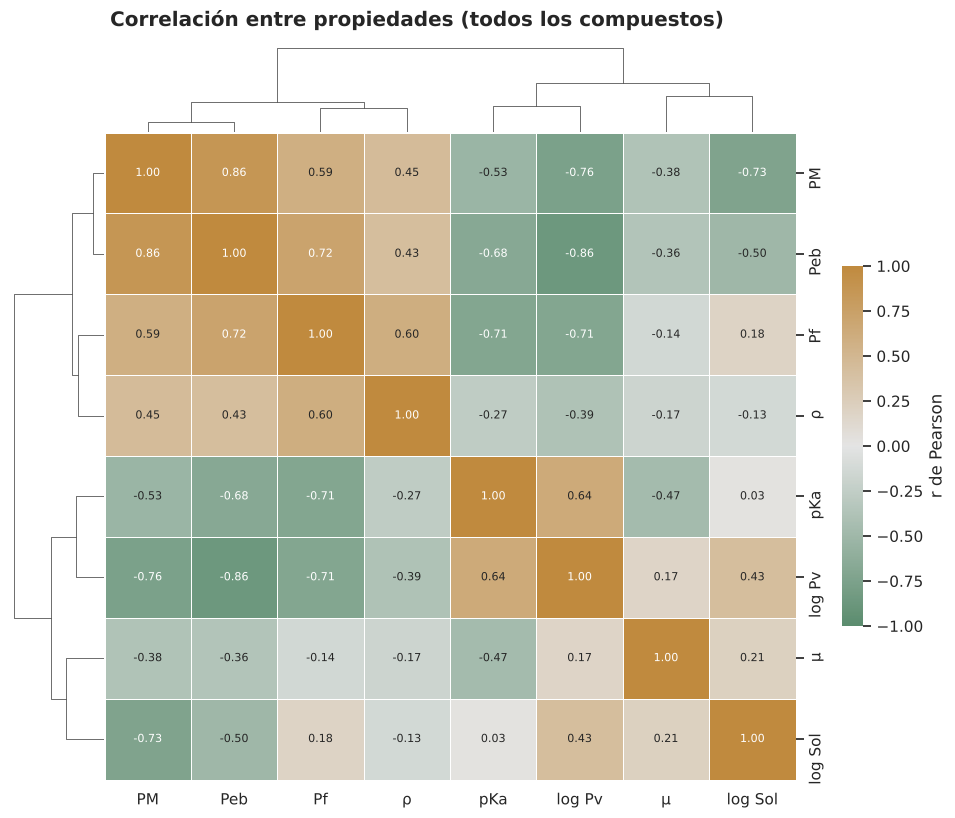

Número mínimo de compuestos por pareja: 11
Parejas más fuertes (|r|):
Peb  log Pv    -0.86
PM   Peb        0.86
     log Pv    -0.76
     log Sol   -0.73
Pf   Peb        0.72
     pKa       -0.71


In [ ]:
# Relación química: qué propiedades varían juntas. Se leen primero los valores cercanos a 1 o a -1
# para elegir las parejas que se grafican después (por ejemplo PM–Peb por las fuerzas de London).
# Se usan TODOS los compuestos distintos del Excel (sustancias, productos y reactivos, sin repetir CAS)
# para tener más datos por pareja; la relación entre propiedades no depende del papel en la reacción.
comp = pd.concat([sus.rename(columns={'Sustancia': 'Nombre'}),
                  rx.rename(columns={'Producto': 'Nombre', 'CAS producto': 'CAS'}),
                  ob.rename(columns={'Reactante principal': 'Nombre', 'CAS reactante': 'CAS'})])
comp = comp.drop_duplicates(subset='CAS')[PROPS].copy()      # un compuesto = una fila
comp['Pv'] = np.log10(comp['Pv'].where(comp['Pv'] > 0))       # log10: Pv abarca muchos órdenes de magnitud
comp['Sol'] = np.log10(comp['Sol'].where(comp['Sol'] > 0))    # igual para la solubilidad
comp = comp.rename(columns={'Pv': 'log Pv', 'Sol': 'log Sol'})

corr = comp.corr(method='pearson', min_periods=5)   # min_periods=5: con menos de 5 pares no se calcula
n_par = comp.notna().astype(int).T @ comp.notna().astype(int)   # n de compuestos con ambos datos
sin_dato = corr.columns[corr.isna().any()]          # variables con alguna pareja sin cálculo
if len(sin_dato):                                   # if: el dendrograma no admite celdas vacías
    print('Se excluyen por falta de pares (n < 5):', list(sin_dato))
    corr = corr.drop(index=sin_dato, columns=sin_dato); n_par = n_par.loc[corr.index, corr.columns]

g = sns.clustermap(corr, cmap=DIV, vmin=-1, vmax=1, center=0, annot=True, fmt='.2f',
                   annot_kws={'size': 8}, linewidths=0.6, linecolor='white', figsize=(8.5, 8),
                   dendrogram_ratio=0.12, cbar_pos=(1.0, 0.25, 0.025, 0.45),
                   cbar_kws={'label': 'r de Pearson'})   # matriz completa y cuadrada, sin máscara
g.ax_heatmap.set_xlabel(''); g.ax_heatmap.set_ylabel('')     # los nombres ya están en las marcas
g.figure.suptitle('Correlación entre propiedades (todos los compuestos)', y=1.02, fontweight='bold')
guardar(g.figure, '01_mapa_correlacion'); plt.show()

pares = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()   # cada pareja una sola vez
print('Número mínimo de compuestos por pareja:', int(n_par.values.min()))
print('Parejas más fuertes (|r|):')
print(pares.reindex(pares.abs().sort_values(ascending=False).index).head(6).round(2).to_string())

**Tipo de gráfica.** Mapa de calor con dendrograma. El color resume el coeficiente r de Pearson de cada pareja y el árbol de la izquierda y de arriba reúne las propiedades con comportamiento similar. Paleta divergente suave: verde (negativo), gris claro (cero) y ocre (positivo).

**Interpretación.** Para los hidrocarburos destacan dos parejas: PM–Peb (r = 0.86) y Peb–log Pv (r = −0.86). En moléculas apolares la única atracción entre ellas son las fuerzas de London, que crecen con el número de electrones; por eso, a más masa, más alto el punto de ebullición y más baja la presión de vapor. PM–log Sol (−0.73) muestra que los hidrocarburos grandes son aún menos solubles en agua. El dendrograma separa un bloque de "tamaño" (PM, Peb, Pf, ρ) de otro de "volatilidad" (log Pv, pKa).

### Gráfica 2. Mapa de calor de las propiedades normalizadas de las sustancias

**Qué hace el código.**
- Se parte de la tabla de las 10 sustancias. El pKa no entra en este mapa (sí está en el mapa de correlación) y se transforman Pv y solubilidad a log₁₀.
- Si una propiedad tiene vacíos en alguna sustancia, **se retira** y se informa, para que todas las columnas tengan las 10 sustancias.
- Cada propiedad se lleva a la escala **0–1 (normalización mín–máx)**: (x − mín) / (máx − mín). Así se pueden poner en la misma figura magnitudes con unidades distintas.
- El mapa de calor muestra el valor 0–1 en cada celda, con las sustancias ordenadas por PM.

Propiedades excluidas por datos faltantes: {'Pf': 2, 'μ': 1}


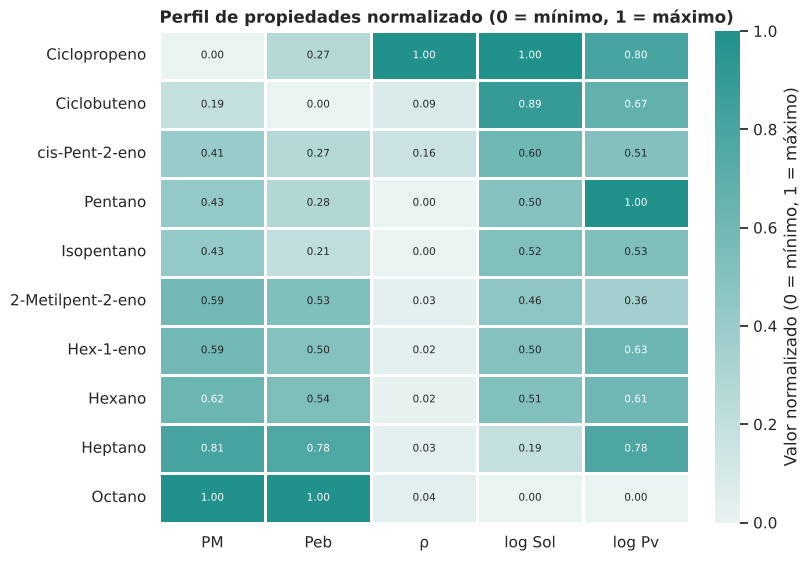

In [ ]:
# Relación química: perfil de cada sustancia en todas sus propiedades a la vez (cuál es la más pesada,
# la más volátil, la más soluble). Cada propiedad se escala de 0 (mínimo) a 1 (máximo).
# Decisión sobre vacíos (para que no aparezcan celdas grises "N/A" y se vean las 10 sustancias):
#   1) pKa se excluye porque no se comparan pKa entre sustancias;
#   2) se excluye toda propiedad a la que le falte el dato en alguna sustancia (se informa cuál).
m = sus.set_index('Sustancia')[[p for p in PROPS if p != 'pKa']].copy()
m['Pv'] = np.log10(m['Pv']); m['Sol'] = np.log10(m['Sol'])   # log10 para comparar órdenes de magnitud
faltan = m.isna().sum()                                        # vacíos por propiedad
quitar_prop = faltan[faltan > 0].index.tolist()                # propiedades incompletas
m = m.drop(columns=quitar_prop)                                # drop: se quitan esas columnas
print('Propiedades excluidas por datos faltantes:', {p: int(faltan[p]) for p in quitar_prop} or 'ninguna')

norm = (m - m.min()) / (m.max() - m.min())                     # normalización mín–máx por columna
norm = norm.loc[[s for s in ORDEN if s in norm.index]]         # filas en orden de PM
norm.columns = [{'Pv': 'log Pv', 'Sol': 'log Sol'}.get(x, x) for x in norm.columns]
fig, ax = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
sns.heatmap(norm, cmap=SEQ, vmin=0, vmax=1, annot=True, fmt='.2f',
            annot_kws={'size': 7.5}, linewidths=0.8, linecolor='white',
            cbar_kws={'label': 'Valor normalizado (0 = mínimo, 1 = máximo)'}, ax=ax)
ax.set_xlabel(''); ax.set_ylabel('')                           # sin títulos repetidos
ax.set_title('Perfil de propiedades normalizado (0 = mínimo, 1 = máximo)')
guardar(fig, '02_propiedades_normalizadas'); plt.show()

**Tipo de gráfica.** Mapa de calor con escala secuencial verde azulado: claro = valor más bajo del grupo, oscuro = valor más alto.

**Interpretación.** Cada celda es (x − mínimo)/(máximo − mínimo): 0 es el hidrocarburo con el valor más bajo de esa propiedad y 1 el más alto. El octano ocupa el extremo de los alcanos grandes (1.00 en PM y Peb, 0.00 en solubilidad y presión de vapor), mientras que el ciclopropeno es el más pequeño y el más soluble.

### Gráfica 3. Líneas de doble eje: propiedades de las sustancias ordenadas por PM

**Qué hace el código.**
- Se grafican tres parejas en tres paneles: **Pf y Peb**, **PM y ρ**, y **Pv y Peb**.
- El eje x lleva los hidrocarburos ordenados por PM.
- Cada panel tiene **dos ejes y**: el izquierdo para la primera propiedad (línea continua) y uno derecho creado con `twinx` para la segunda (línea discontinua). Así se comparan tendencias de magnitudes con unidades diferentes.
- Los puntos vacíos se retiran antes de trazar, por lo que **la línea sigue continua** aunque falte un dato. Pv se dibuja en escala logarítmica.
- Se imprime el **Spearman** de cada pareja para cuantificar si suben o bajan juntas.

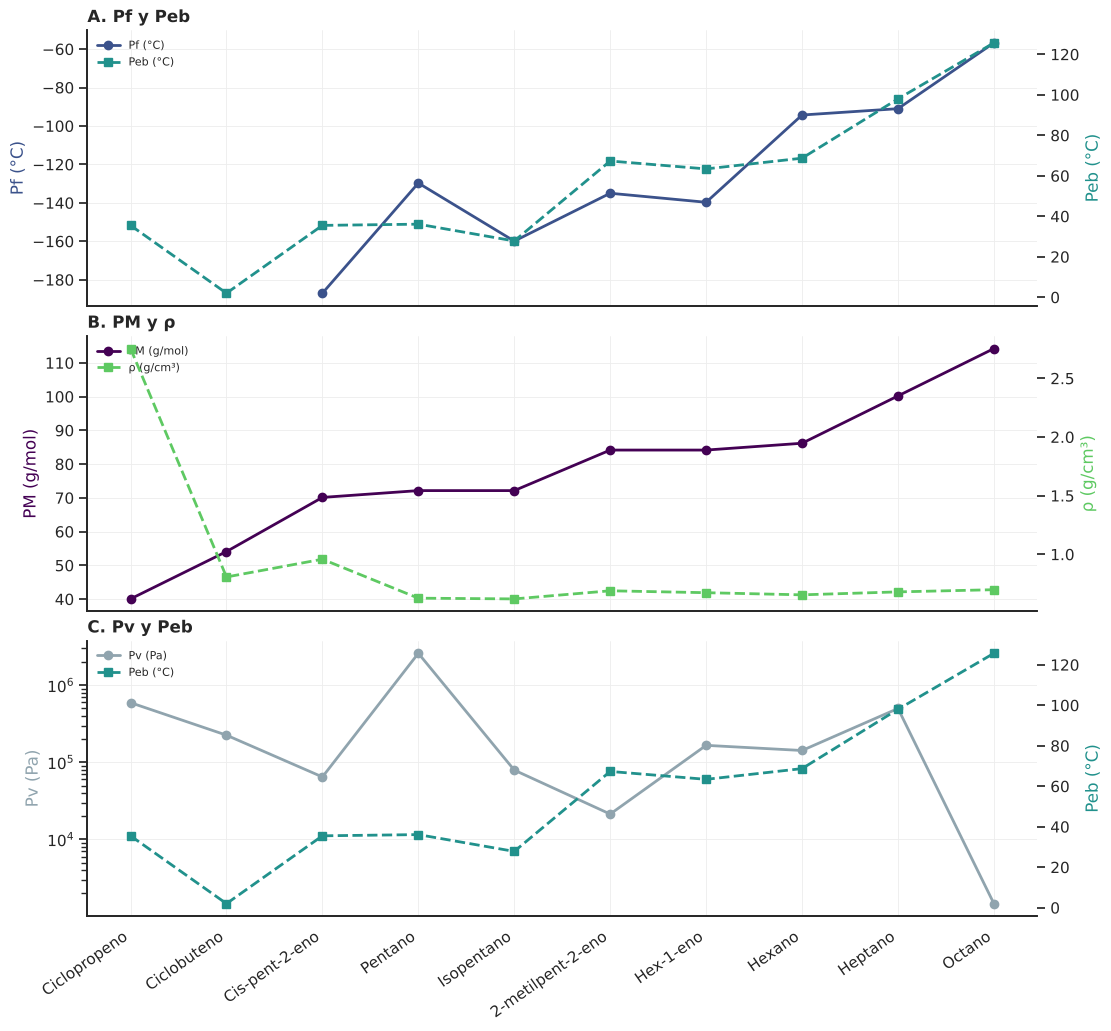

Pf–Peb: Spearman ρ = 0.90 (p = 0.002, n = 8)
PM–ρ: Spearman ρ = -0.39 (p = 0.265, n = 10)
Pv–Peb: Spearman ρ = -0.29 (p = 0.424, n = 10)


In [ ]:
# Relación química: cómo cambian dos propiedades a la vez cuando aumenta el peso molecular.
# Doble eje porque las dos propiedades tienen escalas distintas (si no, una línea quedaría aplastada).
PARES = [('Pf', 'Peb'), ('PM', 'ρ'), ('Pv', 'Peb')]                           # parejas elegidas a partir del mapa de correlación
MARCA = {0: 'o', 1: 's'}                     # marcador distinto para cada eje
d = sus.set_index('Sustancia').loc[ORDEN]       # filas en orden creciente de PM
x = np.arange(len(ORDEN))                       # posición de cada sustancia en el eje x
NOMBRE = [s.replace('Ácido ', '').capitalize() for s in ORDEN]   # nombres cortos para el eje
fig, axs = plt.subplots(3, 1, figsize=(11, 10.2), sharex=True, constrained_layout=True)
for i, (a, b) in enumerate(PARES):              # for: un panel por pareja
    ax = axs[i]
    ok = d[a].notna().values                    # solo sustancias con dato: la línea no se corta
    ax.plot(x[ok], d[a][ok], marker=MARCA[0], color=COL_VAR[a], lw=2, label=UNIDAD[a])
    ax.set_ylabel(UNIDAD[a], color=COL_VAR[a])
    ax2 = ax.twinx()                            # twinx: segundo eje y que comparte el eje x
    ok = d[b].notna().values
    ax2.plot(x[ok], d[b][ok], marker=MARCA[1], ls='--', color=COL_VAR[b], lw=2, label=UNIDAD[b])
    ax2.set_ylabel(UNIDAD[b], color=COL_VAR[b]); ax2.grid(False)
    for eje, var in ((ax, a), (ax2, b)):
        if var in ('Pv', 'Sol'):                # if: Pv y Sol abarcan varios órdenes de magnitud
            eje.set_yscale('log')
    ax.set_title(f'{chr(65 + i)}. {UNIDAD[a].split(" (")[0]} y {UNIDAD[b].split(" (")[0]}')
    lin = ax.get_legend_handles_labels(); lin2 = ax2.get_legend_handles_labels()
    ax.legend(lin[0] + lin2[0], lin[1] + lin2[1], loc='upper left', fontsize=8, frameon=False)
    ax.set_xticks(x); ax.set_xticklabels(NOMBRE, rotation=35, ha='right')
guardar(fig, '03_doble_eje_propiedades'); plt.show()
for a, b in PARES:                              # correlación de cada pareja en las 10 sustancias
    v = d[[a, b]].dropna()
    r, p = stats.spearmanr(v[a], v[b])          # Spearman: tendencia monótona, robusta con n = 10
    print(f'{a}–{b}: Spearman ρ = {r:.2f} (p = {p:.3f}, n = {len(v)})')

**Tipo de gráfica.** Tres paneles de líneas con doble eje. El eje x son los 10 hidrocarburos ordenados por peso molecular; cada propiedad tiene su propio eje porque sus escalas son distintas.

**Interpretación.** **A.** El Pf y el Peb suben juntos al crecer la molécula (Spearman ρ = 0.90, p = 0.002, n = 8); el isopentano baja en ambas por su ramificación. **B.** El PM crece de forma continua, pero la densidad se mantiene entre 0.62 y 0.96 g/cm³; el único valor fuera de lugar es el del ciclopropeno, por eso la correlación no es significativa (ρ = −0.39, p = 0.27). **C.** La presión de vapor debería bajar cuando sube el Peb, pero el pentano y el heptano rompen el patrón (ρ = −0.29, p = 0.42)

### Gráfica 4. Tendencia homóloga: punto de ebullición frente al número de carbonos

**Qué hace el código.**
- Se crean dos diccionarios: el **número de carbonos** de cada hidrocarburo y su **grupo estructural** (alcano lineal, ramificado, alqueno o cicloalqueno).
- La regresión lineal **Peb = a·nC + b** se ajusta **solo con los alcanos lineales** (pentano, hexano, heptano y octano), que forman una serie homóloga verdadera; los demás grupos se dibujan como comparación.
- Cada grupo tiene su propio marcador; los alcanos lineales van en color y los demás en gris. Cada punto lleva el nombre del compuesto.
- Se imprimen la **pendiente** (°C que aumenta el Peb por cada carbono añadido), R², el valor p y n.

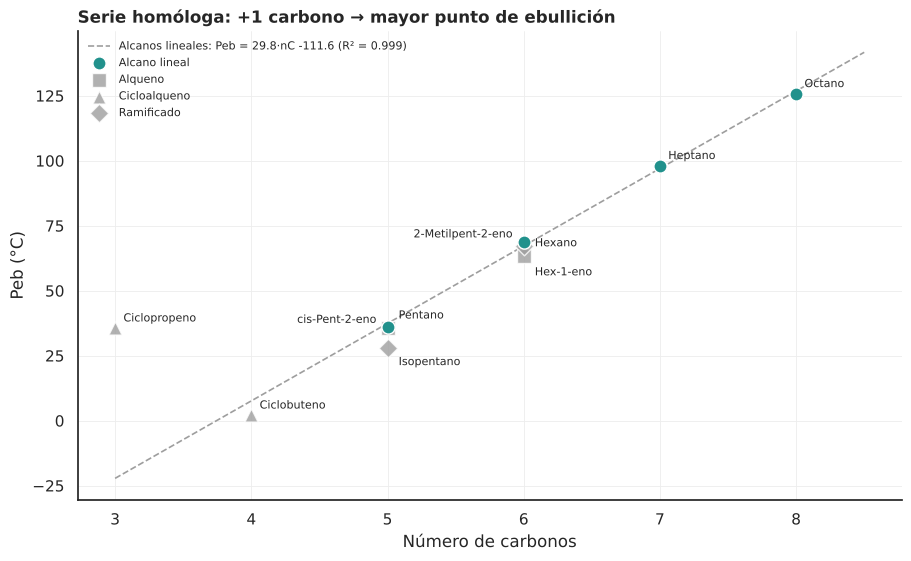

Pendiente = 29.8 °C por carbono | R² = 0.999 | p = 0.0007 | n = 4


In [ ]:
# Relación química: en una serie homóloga cada CH2 añade superficie de contacto → más fuerzas de London
# → mayor punto de ebullición. La ramificación y los anillos tensionados se apartan de la tendencia.
N_C = {'Pentano': 5, 'Isopentano': 5, 'Hexano': 6, 'Heptano': 7, 'Octano': 8, 'cis-Pent-2-eno': 5,
       '2-Metilpent-2-eno': 6, 'Hex-1-eno': 6, 'Ciclopropeno': 3, 'Ciclobuteno': 4}   # carbonos por fórmula
GRUPO = {'Pentano': 'Alcano lineal', 'Hexano': 'Alcano lineal', 'Heptano': 'Alcano lineal', 'Octano': 'Alcano lineal',
         'Isopentano': 'Ramificado', '2-Metilpent-2-eno': 'Ramificado', 'cis-Pent-2-eno': 'Alqueno',
         'Hex-1-eno': 'Alqueno', 'Ciclopropeno': 'Cicloalqueno', 'Ciclobuteno': 'Cicloalqueno'}
d = sus.assign(nC=sus['Sustancia'].map(N_C), Grupo=sus['Sustancia'].map(GRUPO))
lin = d[d['Grupo'] == 'Alcano lineal']                      # la recta se ajusta solo a los lineales
res = stats.linregress(lin['nC'], lin['Peb'])                # pendiente, intercepto, r y p-valor
fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
xs = np.linspace(3, 8.5, 50)
ax.plot(xs, res.intercept + res.slope * xs, color=GRIS, ls='--', lw=1.2,
        label=f'Alcanos lineales: Peb = {res.slope:.1f}·nC {res.intercept:+.1f} (R² = {res.rvalue**2:.3f})')
MARK = {'Alcano lineal': 'o', 'Ramificado': 'D', 'Alqueno': 's', 'Cicloalqueno': '^'}
for gr, sub in d.groupby('Grupo'):                         # un tipo de marcador por familia estructural
    ax.scatter(sub['nC'], sub['Peb'], s=90, marker=MARK[gr], color=COL_VAR['Peb'] if gr == 'Alcano lineal' else GRIS,
               edgecolor='white', label=gr, alpha=1 if gr == 'Alcano lineal' else 0.8,
               zorder=4 if gr == 'Alcano lineal' else 3)   # los alcanos lineales quedan al frente
# Posición de cada etiqueta (dx, dy, alineación) para que los nombres con igual nC no se encimen.
POS = {'Pentano': (8, 6, 'left'), 'cis-Pent-2-eno': (-8, 4, 'right'), 'Isopentano': (8, -12, 'left'),
       'Hexano': (8, -3, 'left'), '2-Metilpent-2-eno': (-8, 6, 'right'), 'Hex-1-eno': (8, -14, 'left')}
for _, f in d.iterrows():                                  # etiqueta con el nombre de cada sustancia
    dx, dy, al = POS.get(f['Sustancia'], (6, 5, 'left'))   # .get: posición por defecto si no está en POS
    ax.annotate(f['Sustancia'], (f['nC'], f['Peb']), xytext=(dx, dy), textcoords='offset points', fontsize=8, ha=al)
ax.set_xlabel('Número de carbonos'); ax.set_ylabel(UNIDAD['Peb'])
ax.set_title('Serie homóloga: +1 carbono → mayor punto de ebullición'); ax.legend(fontsize=8, frameon=False)
guardar(fig, '04_tendencia_homologa'); plt.show()
print(f'Pendiente = {res.slope:.1f} °C por carbono | R² = {res.rvalue**2:.3f} | p = {res.pvalue:.2g} | n = {len(lin)}')

**Tipo de gráfica.** Diagrama de dispersión con una recta de referencia ajustada solo a los alcanos lineales; la forma del marcador indica el tipo de hidrocarburo.

**Interpretación.** Cada carbono que se agrega a la cadena lineal sube el punto de ebullición en unos 29.8 °C (R² = 0.999, p = 0.0007), porque la molécula tiene más superficie de contacto y más fuerzas de London. Ojo: la recta se ajusta con solo 4 alcanos. La ramificación lo baja: el isopentano hierve a 27.8 °C, 8.3 °C menos que el pentano (36.1 °C), porque su forma es más compacta. El hex-1-eno (63.4 °C) queda un poco por debajo del hexano (68.7 °C). El ciclopropeno (35.5 °C en el Excel) se aleja mucho de la tendencia.

### Gráfica 5. Tendencia: peso molecular frente a punto de ebullición de los productos

**Qué hace el código.**
- Se usan los **productos de las reacciones** que tienen tanto PM como Peb.
- regresion ajusta la recta Peb = a·PM + b por mínimos cuadrados (sin banda de confianza) y la dibuja sobre los puntos.
- La salida reporta n, la ecuación, **R²**, el valor **p** y los coeficientes de Pearson y Spearman.

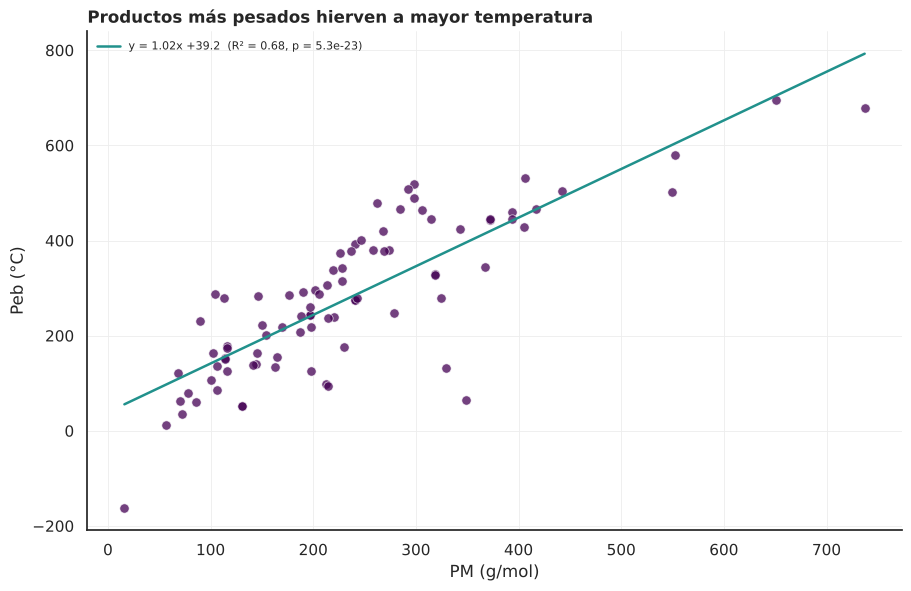

n = 88 | y = 1.022x +39.25 | R² = 0.680 | p = 5.26e-23
Pearson r = 0.82 (p = 5.3e-23) | Spearman ρ = 0.80 (p = 3.4e-21)


In [ ]:
# Relación química: a mayor PM, más electrones y superficie → fuerzas de London más fuertes → mayor Peb.
d = rx.dropna(subset=['PM', 'Peb'])
regresion(d, 'PM', 'Peb', UNIDAD['Peb'], 'Productos más pesados hierven a mayor temperatura', '05_PM_vs_Peb', grupo=None)   # función definida en la sección 2

**Tipo de gráfica.** Diagrama de dispersión con recta de regresión: dos variables numéricas
**Interpretación.** Para los 88 productos con ambos datos, Peb ≈ 1.02·PM + 39 (R² = 0.68, p = 5×10⁻²³; Pearson 0.82, Spearman 0.80). Es decir, cada 100 g/mol adicionales suben el punto de ebullición unos 102 °C, y el PM explica el 68 % de la variación. Los puntos por debajo de la recta corresponden a productos poco polares para su tamaño; el punto aislado de 16 g/mol y −161 °C es el metano.

### Gráfica 6. Relación estructural: peso molecular frente a densidad de los productos

**Qué hace el código.**
- Mismo procedimiento que la gráfica anterior, ahora con la **densidad** de los productos.
- Comparar Pearson con Spearman ayuda a saber si la relación es realmente lineal o si depende de unos pocos valores extremos.

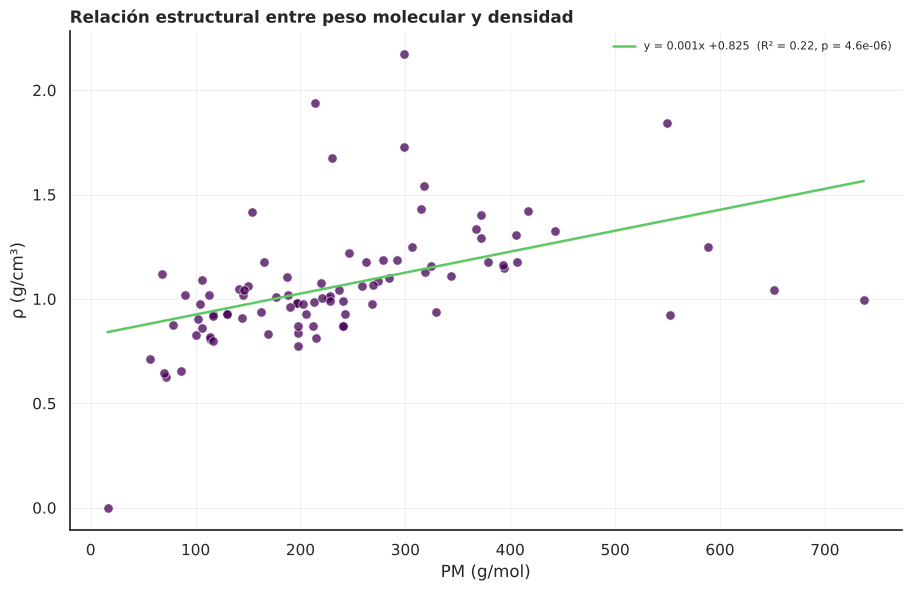

n = 89 | y = 0.001004x +0.8251 | R² = 0.215 | p = 4.60e-06
Pearson r = 0.46 (p = 4.6e-06) | Spearman ρ = 0.63 (p = 2.9e-11)


In [ ]:
# Relación química: la densidad depende de la masa por volumen molecular; átomos pesados (halógenos, O, metales) la suben más que el PM por sí solo.
d = rx.dropna(subset=['PM', 'ρ'])
regresion(d, 'PM', 'ρ', UNIDAD['ρ'], 'Relación estructural entre peso molecular y densidad', '06_PM_vs_densidad', grupo=None)   # función definida en la sección 2

**Tipo de gráfica.** Diagrama de dispersión con recta de regresión.

**Interpretación.** La tendencia es positiva pero débil: ρ ≈ 0.001·PM + 0.83 (R² = 0.22, p = 5×10⁻⁶, n = 89). Spearman (0.63) supera a Pearson (0.46): la densidad sí aumenta con el tamaño, pero no en línea recta. Los productos por encima de 1.5 g/cm³ contienen heteroátomos pesados (O, halógenos, metales), que suben la densidad mucho más que unos cuantos carbonos adicionales.

### Gráfica 7. Volatilidad: punto de ebullición frente a presión de vapor

**Qué hace el código.**
- Se toman reactivos y productos con Peb y Pv, y se excluyen los Pv iguales a 0, porque el logaritmo de 0 no existe.
- Pv se convierte a **log₁₀**, porque así su relación con el punto de ebullición se vuelve aproximadamente lineal.
- regresion ajusta la recta y colorea los puntos por conjunto.

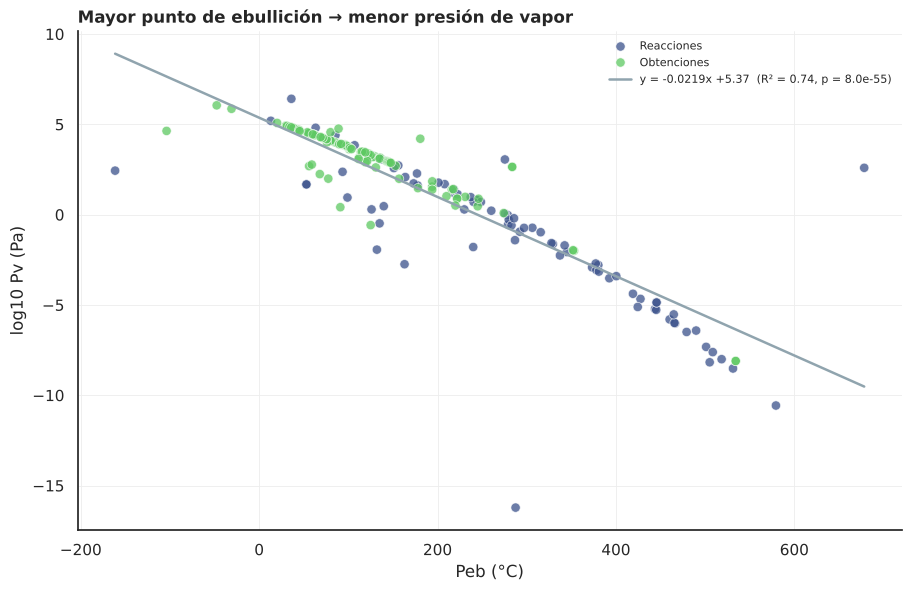

n = 184 | y = -0.02194x +5.369 | R² = 0.738 | p = 8.03e-55
Pearson r = -0.86 (p = 8.0e-55) | Spearman ρ = -0.90 (p = 3.6e-67)


In [ ]:
# Relación química: ambas miden la fuerza de las interacciones intermoleculares; si cuesta más separar las moléculas (Peb alto), pocas pasan al vapor (Pv baja). Se usan productos y reactivos; Pv en log10.
d = ambos.dropna(subset=['Peb', 'Pv'])
d = d[d['Pv'] > 0].assign(Pv=np.log10(d['Pv'][d['Pv'] > 0]))   # log10: Pv abarca muchos órdenes de magnitud
regresion(d, 'Peb', 'Pv', 'log10 Pv (Pa)', 'Mayor punto de ebullición → menor presión de vapor', '07_Peb_vs_Pv', grupo='Conjunto')   # función definida en la sección 2

**Tipo de gráfica.** Diagrama de dispersión con recta de regresión; reactivos y productos con su color, y Pv en log10.

**Interpretación.** log Pv = −0.022·Peb + 5.37 (R² = 0.74; Pearson −0.86, Spearman −0.90; n = 184). Por cada 100 °C de Peb, la presión de vapor cae unas 160 veces. Reactivos y productos se alinean sobre la misma recta, lo que confirma que es una relación física general: si cuesta más separar las moléculas, menos de ellas pasan al vapor.

### Gráfica 8. Frecuencia de cada tipo de reacción: reacciones frente a obtenciones

**Qué hace el código.**
- crosstab con normalize=columns convierte los conteos en **proporciones dentro de cada conjunto**; así las reacciones y las obtenciones se comparan en la misma escala.
- Los mecanismos se ordenan de más a menos frecuente.
- Se dibujan **columnas agrupadas** verticales, con los nombres girados 30°.
- La tabla impresa muestra los conteos originales de cada mecanismo.

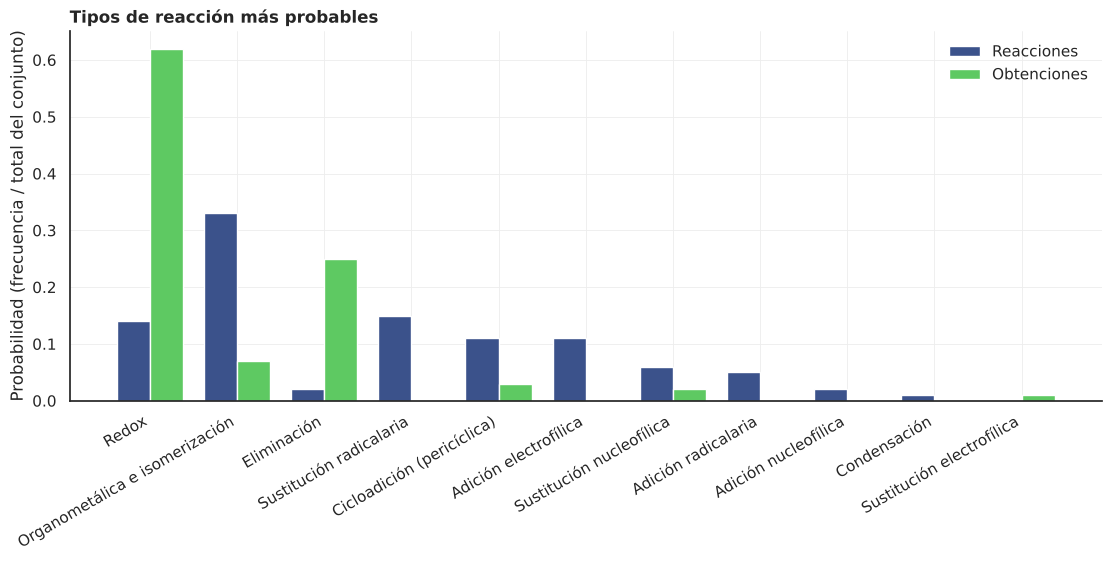

Conjunto                        Obtenciones  Reacciones
Tipo de reacción                                       
Redox                                    62          14
Organometálica e isomerización            7          33
Eliminación                              25           2
Sustitución radicalaria                   0          15
Cicloadición (pericíclica)                3          11
Adición electrofílica                     0          11
Sustitución nucleofílica                  2           6
Adición radicalaria                       0           5
Adición nucleofílica                      0           2
Condensación                              0           1
Sustitución electrofílica                 1           0


In [ ]:
# Relación química: qué tipo de transformación es más probable cuando la sustancia reacciona (reactivo)
# y cuando se forma (producto). Variable categórica → barras AGRUPADAS (no apiladas), sin números encima.
tabla = pd.crosstab(ambos['Tipo de reacción'], ambos['Conjunto'], normalize='columns')   # proporciones
orden = tabla.sum(axis=1).sort_values(ascending=False).index.tolist()                        # de mayor a menor
tabla = tabla.loc[orden]

fig, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)
x = np.arange(len(orden)); w = 0.38                      # posiciones de las barras agrupadas
for i, conj in enumerate(['Reacciones', 'Obtenciones']):
    ax.bar(x + (i - 0.5) * w, tabla[conj], width=w, color=COL_CONJ[conj], label=conj)
ax.set_xticks(x); ax.set_xticklabels(orden, rotation=30, ha='right')
ax.set_ylabel('Probabilidad (frecuencia / total del conjunto)'); ax.set_xlabel('')
ax.set_title('Tipos de reacción más probables'); ax.legend(frameon=False)
guardar(fig, '08_tipos_reaccion'); plt.show()
print(pd.crosstab(ambos['Tipo de reacción'], ambos['Conjunto']).loc[orden].to_string())

**Tipo de gráfica.** Gráfico de barras agrupadas: variable categórica (tipo de reacción) en dos conjuntos; se usan proporciones porque cada conjunto tiene su propio total.

**Interpretación.** Cada reacción se clasificó por su mecanismo principal. Además de los 9 tipos del profesor se necesitaron dos categorías: **cicloadición (pericíclica)**, para las Diels–Alder del ciclopropeno, y **organometálica e isomerización**, para las reacciones mediadas por metales (activación C–H con Rh, Ir o Pd). Cuando los hidrocarburos **reaccionan** domina lo organometálico (33 %), porque un enlace C–H de alcano casi no reacciona sin un metal; le siguen la sustitución radicalaria (15 %), típica de alcanos, y la adición electrofílica y la cicloadición (11 % cada una), típicas de alquenos. Para **obtenerlos** domina el redox (62 %: hidrogenación de alquenos y alquinos, reducción de haluros y desoxigenación), seguido de la eliminación (25 %), que forma los dobles enlaces.

### Gráfica 9. Probabilidad del medio de reacción

**Qué hace el código.**
- Para cada conjunto se divide el número de registros de cada medio entre los **registros que sí reportan medio**.
- wilson añade el **IC 95 %** de cada proporción.
- Se grafican **columnas agrupadas con barras de error**: la barra es la probabilidad y la línea vertical es el intervalo. Si los intervalos de dos medios no se cruzan, su diferencia es clara.
- Se imprime la tabla con n, P y los límites del intervalo.

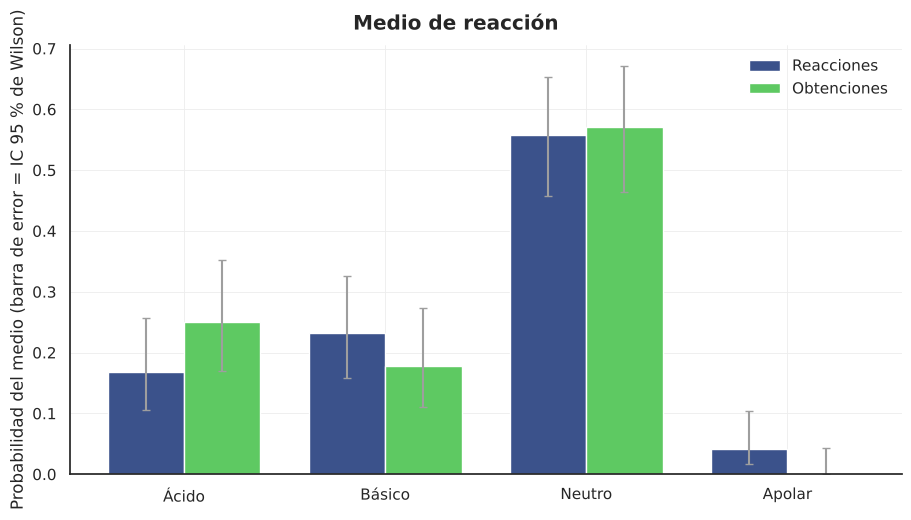

   Conjunto  Medio  n    P   lo   hi
Obtenciones  Ácido 21 0.25 0.17 0.35
Obtenciones Básico 15 0.18 0.11 0.27
Obtenciones Neutro 48 0.57 0.46 0.67
Obtenciones Apolar  0 0.00 0.00 0.04
 Reacciones  Ácido 16 0.17 0.11 0.26
 Reacciones Básico 22 0.23 0.16 0.33
 Reacciones Neutro 53 0.56 0.46 0.65
 Reacciones Apolar  4 0.04 0.02 0.10


In [ ]:
# Relación química: en qué medio (ácido, básico, neutro o apolar) ocurren las reacciones de estas sustancias.
# Es categórica con 4 categorías; se calcula la probabilidad con su intervalo de confianza de Wilson.
filas = []
for conj, g in ambos.groupby('Conjunto'):            # for: un cálculo por conjunto
    n_tot = g['Medio'].notna().sum()                  # solo reacciones con medio conocido
    for m in MEDIOS:
        p, lo, hi = wilson((g['Medio'] == m).sum(), n_tot)
        filas.append(dict(Conjunto=conj, Medio=m, n=int((g['Medio'] == m).sum()), P=p, lo=lo, hi=hi))
res = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
x = np.arange(len(MEDIOS)); w = 0.38
for i, conj in enumerate(['Reacciones', 'Obtenciones']):
    t = res[res['Conjunto'] == conj].set_index('Medio').reindex(MEDIOS)
    ax.bar(x + (i - 0.5) * w, t['P'], width=w, color=COL_CONJ[conj], label=conj,
           yerr=[t['P'] - t['lo'], t['hi'] - t['P']], error_kw={'ecolor': GRIS, 'capsize': 3})
ax.set_xticks(x); ax.set_xticklabels(MEDIOS); ax.set_xlabel('')
ax.set_ylabel('Probabilidad del medio (barra de error = IC 95 % de Wilson)'); ax.legend(frameon=False)
fig.suptitle('Medio de reacción', fontweight='bold')
guardar(fig, '09_medio_reaccion'); plt.show()
print(res.round(2).to_string(index=False))

**Tipo de gráfica.** Gráfico de barras agrupadas con barras de error: 4 categorías en 2 conjuntos, con IC 95 % de Wilson.

**Interpretación.** El medio **neutro** es claramente el más probable: 0.56 [0.46–0.65] en reacciones y 0.57 [0.46–0.67] en obtenciones, y su intervalo no se solapa con los demás. Tiene sentido para sustancias apolares sin grupos ácidos ni básicos. Ácido y básico quedan entre 0.17 y 0.25, con intervalos solapados, así que no se puede decir que uno sea más común que el otro.

### Gráfica 10. Relación sustancia × medio de reacción

**Qué hace el código.**
- Para cada conjunto se cuenta cuántas veces aparece cada **pareja sustancia–medio** (crosstab).
- Las filas siguen el orden por PM y los vacíos se rellenan con 0.
- Se dibujan dos mapas de calor (Reacciones y Obtenciones) con el **mismo eje y**, para leer cada hidrocarburo a la misma altura en los dos paneles.

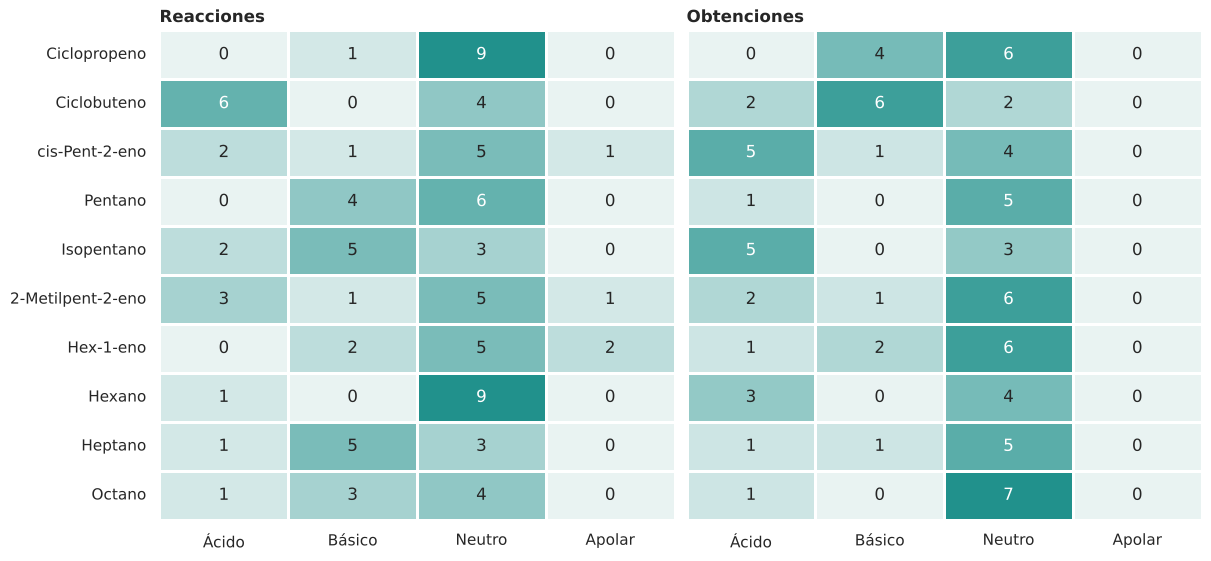

In [ ]:
# Relación química: cada sustancia prefiere ciertos medios según sus grupos funcionales (dos variables
# categóricas → tabla de frecuencias en mapa de calor). Escala secuencial: claro = pocas, oscuro = muchas.
fig, axs = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True, constrained_layout=True)
for ax, conj in zip(axs, ['Reacciones', 'Obtenciones']):
    t = pd.crosstab(ambos[ambos['Conjunto'] == conj]['Sustancia'], ambos[ambos['Conjunto'] == conj]['Medio'])
    t = t.reindex(index=ORDEN, columns=MEDIOS, fill_value=0)   # mismas filas y columnas en ambos paneles
    sns.heatmap(t, cmap=SEQ, annot=True, fmt='d', linewidths=0.8, linecolor='white', cbar=False, ax=ax)
    ax.set_title(conj); ax.set_xlabel(''); ax.set_ylabel('')
guardar(fig, '10_sustancia_medio'); plt.show()

**Tipo de gráfica.** Mapa de calor de una tabla de contingencia: dos variables categóricas; el número es la frecuencia.

**Interpretación.** El ciclopropeno y el hexano reaccionan casi siempre en medio neutro (9 de 10). El ciclobuteno es el que más reacciona en medio ácido (6), y el isopentano y el heptano en medio básico (5 cada uno). En las obtenciones domina el neutro (por ejemplo el octano 7 de 10, típico de hidrogenaciones); el ciclobuteno se obtiene sobre todo en medio básico (6), en eliminaciones con terc-butóxido, y el cis-pent-2-eno y el isopentano en medio ácido (5 cada uno).

### Gráfica 11. Relación sustancia × tipo de reacción

**Qué hace el código.**
- Solo con el conjunto Reacciones (10 por hidrocarburo) se arma la tabla **hidrocarburo × mecanismo**.
- Las columnas van de la más a la menos frecuente.
- El mapa de calor escribe en cada celda cuántas reacciones de ese tipo tiene cada hidrocarburo.

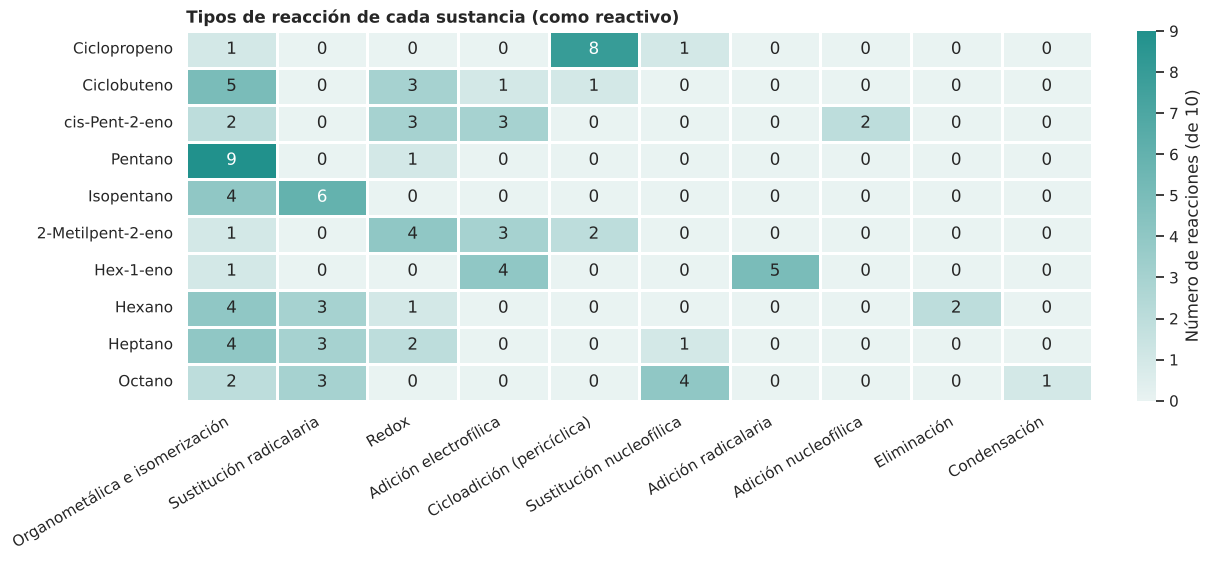

In [ ]:
# Relación química: qué tipo de reacción es típico de cada sustancia (reactividad según su estructura).
t = pd.crosstab(rx['Sustancia'], rx['Tipo de reacción']).reindex(index=ORDEN, fill_value=0)
t = t[t.sum().sort_values(ascending=False).index]          # columnas de la familia más a la menos frecuente
fig, ax = plt.subplots(figsize=(12, 5.5), constrained_layout=True)
sns.heatmap(t, cmap=SEQ, annot=True, fmt='d', linewidths=0.8, linecolor='white',
            cbar_kws={'label': 'Número de reacciones (de 10)'}, ax=ax)
ax.set_xlabel(''); ax.set_ylabel(''); ax.set_title('Tipos de reacción de cada sustancia (como reactivo)')
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
guardar(fig, '11_sustancia_tipo'); plt.show()

**Tipo de gráfica.** Mapa de calor de una tabla de contingencia.

**Interpretación.** Se ve el efecto de la insaturación. Los **alcanos** reaccionan por vía organometálica (pentano 9 de 10) o radicalaria (isopentano 6), porque sus enlaces C–H solo se rompen con un metal o con un radical. Los **alquenos** reaccionan por adición: el hex-1-eno por adición radicalaria (5, tiol-eno) y electrofílica (4), y el 2-metilpent-2-eno por redox (4, oxidaciones del doble enlace) y adición electrofílica (3). El **ciclopropeno** hace cicloadiciones en 8 de 10 casos: la tensión de su anillo de tres carbonos lo vuelve muy reactivo como dienófilo.

### Gráfica 12. Comparación de distribuciones: reactivos (obtenciones) frente a productos (reacciones)

**Qué hace el código.**
- Se compara la distribución de **PM** y de **densidad** entre reactivos (obtenciones) y productos (reacciones).
- Para que un valor aislado no estire el eje, se descartan los valores por encima de **1.2 × percentil 97**.
- Cada grupo se dibuja como **curva de densidad** (`kdeplot`) con su mediana en línea discontinua.
- La prueba **U de Mann-Whitney** dice si las dos distribuciones difieren, sin suponer normalidad; se imprime su valor p con las medianas.

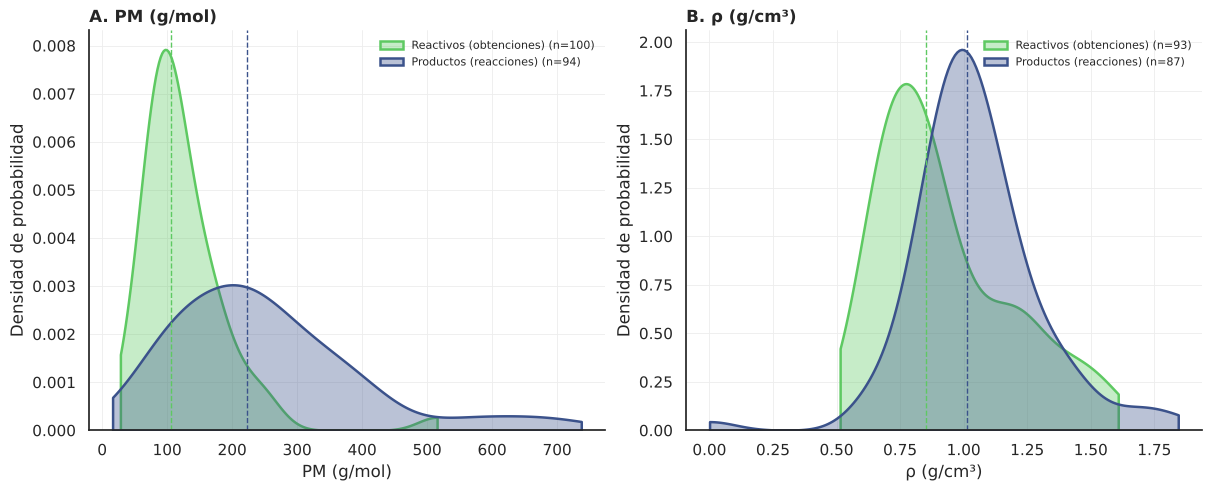

PM: mediana reactivos = 105 | productos = 228 | Mann-Whitney p = 1.01e-14
ρ: mediana reactivos = 0.853 | productos = 1.02 | Mann-Whitney p = 3.66e-05


In [ ]:
# Relación química: al reaccionar, la sustancia se convierte en productos más grandes o más pequeños;
# se comparan las distribuciones (densidad de probabilidad) de PM y ρ de reactivos y productos.
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
for ax, var in zip(axs, ['PM', 'ρ']):                      # un panel por propiedad
    tope = ambos[var].quantile(0.97) * 1.2                  # se recorta el 3 % más extremo solo en el dibujo
    for conj, et in (('Obtenciones', 'Reactivos (obtenciones)'), ('Reacciones', 'Productos (reacciones)')):
        v = ambos.loc[(ambos['Conjunto'] == conj) & (ambos[var] <= tope), var].dropna()
        sns.kdeplot(v, fill=True, alpha=0.35, color=COL_CONJ[conj], lw=1.8, cut=0, ax=ax, label=f'{et} (n={len(v)})')
        ax.axvline(v.median(), color=COL_CONJ[conj], ls='--', lw=1)    # línea = mediana
    ax.set_xlabel(UNIDAD[var]); ax.set_ylabel('Densidad de probabilidad'); ax.legend(fontsize=8, frameon=False)
    ax.set_title(f'{chr(65 + list(axs).index(ax))}. {UNIDAD[var]}')
guardar(fig, '12_reactivos_vs_productos'); plt.show()
for var in ['PM', 'ρ']:                                    # prueba de Mann-Whitney (no supone normalidad)
    a = ob[var].dropna(); b = rx[var].dropna()
    print(f'{var}: mediana reactivos = {a.median():.3g} | productos = {b.median():.3g} | Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.2e}')

**Tipo de gráfica.** Gráfico de densidad: compara la forma de dos distribuciones numéricas; la línea punteada es la mediana.

**Interpretación.** Los productos son más del doble de pesados que los reactivos usados para obtener los hidrocarburos (mediana 228 frente a 105 g/mol; Mann-Whitney p = 1×10⁻¹⁴) y también más densos (1.02 frente a 0.85 g/cm³; p = 4×10⁻⁵). Para obtener un hidrocarburo se parte de moléculas pequeñas parecidas (alquenos, haluros, alcoholes); al reaccionar, el hidrocarburo se une a fragmentos grandes y a menudo con heteroátomos, lo que también sube la densidad.

### Gráfica 13. Distribución de la temperatura máxima de reacción

**Qué hace el código.**
- Se usan las reacciones y obtenciones con **T máxima numérica**.
- El histograma tiene 16 intervalos y se expresa en **probabilidad dentro de cada conjunto** (common_norm=False), con una curva de densidad superpuesta.
- La línea vertical marca **25 °C**, la referencia de temperatura ambiente.
- Por conjunto se imprimen n, la mediana, **P(T > 25 °C)** con su IC de Wilson y los registros sin temperatura.

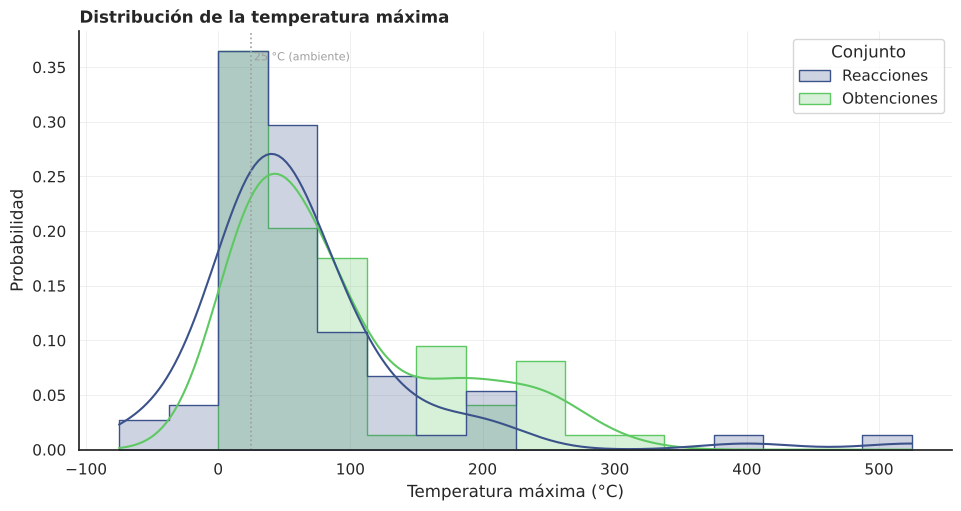

Obtenciones: n = 74 | mediana = 60 °C | P(T > 25 °C) = 0.68 [0.56–0.77] | sin T numérica: 26
Reacciones: n = 74 | mediana = 40 °C | P(T > 25 °C) = 0.57 [0.45–0.67] | sin T numérica: 26


In [ ]:
# Relación química: cuánta energía térmica necesitan las reacciones; T > 25 °C indica calentamiento.
fig, ax = plt.subplots(figsize=(9.5, 5), constrained_layout=True)
sns.histplot(data=ambos.dropna(subset=['T_max']), x='T_max', hue='Conjunto', palette=COL_CONJ, bins=16,
             stat='probability', common_norm=False, kde=True, element='step', alpha=0.25, ax=ax)
ax.axvline(25, color=GRIS, ls=':', lw=1.2); ax.text(27, ax.get_ylim()[1] * 0.93, '25 °C (ambiente)', fontsize=8, color=GRIS)
ax.set_xlabel('Temperatura máxima (°C)'); ax.set_ylabel('Probabilidad'); ax.set_title('Distribución de la temperatura máxima')
guardar(fig, '13_distribucion_temperatura'); plt.show()
for conj, g in ambos.groupby('Conjunto'):
    t = g['T_max'].dropna()
    p, lo, hi = wilson((t > 25).sum(), len(t))
    print(f'{conj}: n = {len(t)} | mediana = {t.median():.0f} °C | P(T > 25 °C) = {p:.2f} [{lo:.2f}–{hi:.2f}] | sin T numérica: {g["T_max"].isna().sum()}')

**Tipo de gráfica.** Histograma con curva de densidad; es la gráfica que el profesor aprobó y se mantiene con los colores del proyecto.

**Interpretación.** La mayoría de las reacciones se concentra entre 0 y 100 °C. Las obtenciones necesitan calor con mayor frecuencia: P(T > 25 °C) = 0.68 [0.56–0.77] y mediana de 60 °C, frente a 0.57 [0.45–0.67] y 40 °C en las reacciones. Los extremos son R-024 (400 °C) y R-025 (525 °C), deshidrogenación y deshidroaromatización del hexano, y, en el otro extremo, reacciones bajo cero como R-065 (−75 °C, hidrogenación iónica) y R-054 (−50 °C, pentenilación de aldehídos), enfriadas para controlar la selectividad.

### Gráfica 14. Temperatura de las reacciones con calentamiento, según el medio

**Qué hace el código.**
- Solo entran los registros **calentados (T > 25 °C)**.
- Se dibuja una caja por medio y conjunto **solo si tiene 5 datos o más**. Con menos, la mediana y los cuartiles no son representativos, y por eso esos grupos se omiten.
- Cada medio va en **su propio panel**, con su propio eje y, porque los rangos de temperatura varían mucho.
- El título de cada panel muestra **P(T > 25 °C)** de ese medio, calculada con todos sus registros con temperatura, y su **IC 95 % de Wilson**.
- La salida lista el número de datos y las estadísticas de cada caja.

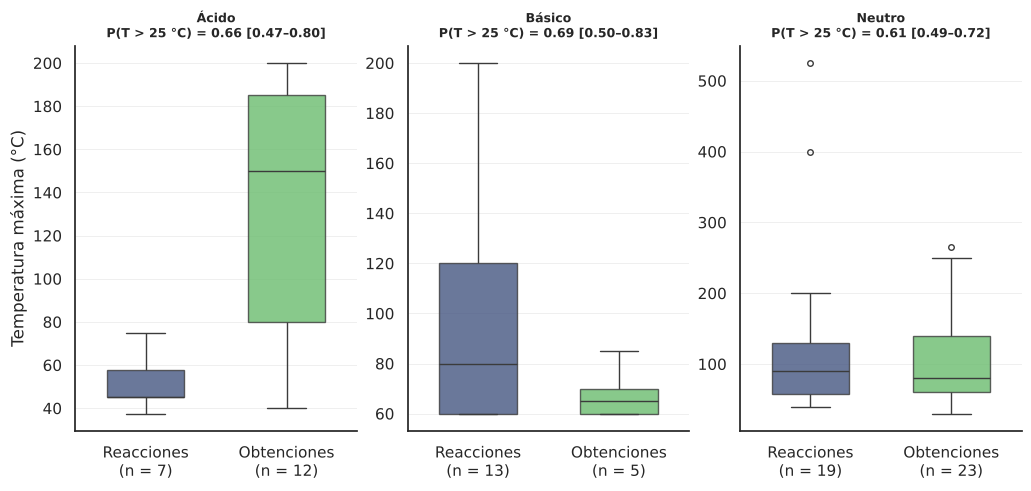

Datos por caja (T > 25 °C):
Conjunto  Obtenciones  Reacciones
Medio                            
Básico              5          13
Neutro             23          19
Ácido              12           7
                    count    50%   min    max
Medio  Conjunto                              
Básico Obtenciones    5.0   65.0  60.0   85.0
       Reacciones    13.0   80.0  60.0  200.0
Neutro Obtenciones   23.0   80.0  30.0  265.0
       Reacciones    19.0   90.0  39.0  525.0
Ácido  Obtenciones   12.0  150.0  40.0  200.0
       Reacciones     7.0   45.0  38.0   75.0


In [ ]:
# Relación química: cuando una reacción necesita calor, ¿a qué temperatura se hace en cada medio?
# Muchas reacciones son a 25 °C (ambiente); esos valores iguales aplastan la caja, por eso se filtran:
# su frecuencia se resume en P(T > 25 °C) del título y la caja muestra solo las que se calientan.
conT = ambos.dropna(subset=['T_max'])                     # reacciones con temperatura numérica
cal = conT[conT['T_max'] > 25]                            # solo las que se calientan
n_caja = cal.groupby(['Medio', 'Conjunto']).size()        # datos en cada caja
MED_T = [m for m in MEDIOS if n_caja.get(m, pd.Series()).max() >= 5]   # al menos una caja con 5 datos
fig, axs = plt.subplots(1, len(MED_T), figsize=(3.4 * len(MED_T), 4.8), constrained_layout=True)
for ax, m in zip(axs, MED_T):                             # un panel por medio, cada uno con su escala
    grupos = [g for g in ['Reacciones', 'Obtenciones'] if n_caja.get((m, g), 0) >= 5]
    d = cal[(cal['Medio'] == m) & cal['Conjunto'].isin(grupos)]
    sns.boxplot(data=d, x='Conjunto', y='T_max', order=grupos, hue='Conjunto', palette=COL_CONJ,
                width=0.55, fliersize=4, legend=False, boxprops={'alpha': 0.8}, ax=ax)
    ax.set_xticks(range(len(grupos)))
    ax.set_xticklabels([f'{g}\n(n = {n_caja[(m, g)]})' for g in grupos])
    todos = conT[conT['Medio'] == m]
    p, lo, hi = wilson((todos['T_max'] > 25).sum(), len(todos))
    ax.set_title(f'{m}\nP(T > 25 °C) = {p:.2f} [{lo:.2f}–{hi:.2f}]', fontsize=9, loc='center')
    ax.set_xlabel(''); ax.set_ylabel('Temperatura máxima (°C)' if m == MED_T[0] else '')
guardar(fig, '14_temperatura_por_medio'); plt.show()
print('Datos por caja (T > 25 °C):'); print(n_caja.unstack(fill_value=0))
print(cal.groupby(['Medio', 'Conjunto'])['T_max'].describe()[['count', '50%', 'min', 'max']].round(0).to_string())

**Tipo de gráfica.** Diagrama de caja: mediana, cuartiles y atípicos de cada grupo; cada medio tiene su propio eje y.

**Interpretación.** Solo se dibujan las reacciones que se calientan (T > 25 °C) y cajas con al menos 5 datos; la frecuencia de las que se hacen a 25 °C está en P(T > 25 °C) de cada título. Los tres medios se calientan con probabilidad parecida (0.61 a 0.69), así que el medio no decide si hay que calentar. Lo que cambia es cuánto: en medio ácido las obtenciones tienen mediana de 150 °C (deshidrataciones de alcoholes), frente a 45 °C en las reacciones.

### Gráfica 15. Probabilidad de usar catalizador y de calentar, por sustancia

**Qué hace el código.**
- Para cada hidrocarburo se calcula la fracción de sus reacciones que **usan catalizador** y la fracción que se **calienta (T > 25 °C)**; esta última solo entre las reacciones con temperatura.
- Cada fracción lleva su **IC 95 % de Wilson** como barra de error.
- Las dos proporciones se muestran como **barras agrupadas** por hidrocarburo, de 0 a 1.
- Se imprimen los valores globales y las probabilidades **condicionales** P(catalizador | calor) y P(catalizador | sin calor).

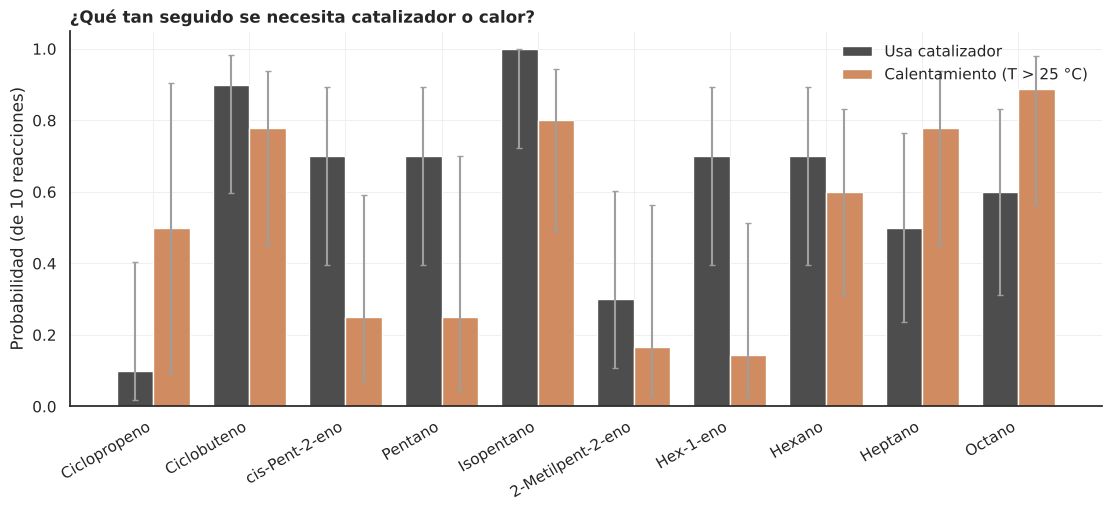

P(catalizador) = 0.62 (n = 100) | P(T > 25 °C) = 0.57 (n = 74)
P(catalizador | calor) = 0.83 (n = 42) | P(catalizador | sin calor) = 0.56 (n = 32)


In [ ]:
# Relación química: las sustancias poco reactivas necesitan catalizador o calor para reaccionar.
# Son variables sí/no (categóricas) → proporción con IC 95 % de Wilson, en barras agrupadas.
filas = []
for s_, g in rx.groupby('Sustancia'):
    for var, et in (('Usa catalizador', 'Usa catalizador'), ('Calor', 'Calentamiento (T > 25 °C)')):
        if var == 'Usa catalizador':                  # if: catalizador se conoce en todas las reacciones
            serie = g['Usa catalizador']
        else:                                         # el calor solo se evalúa donde hay T numérica
            serie = g['T_max'].dropna() > 25
        p, lo, hi = wilson(int(serie.sum()), len(serie))
        filas.append(dict(Sustancia=s_, Variable=et, P=p, lo=lo, hi=hi))
t = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
x = np.arange(len(ORDEN)); w = 0.38
for i, (et, col) in enumerate(zip(t['Variable'].unique(), [COL_SI['cat'], COL_SI['calor']])):
    s = t[t['Variable'] == et].set_index('Sustancia').reindex(ORDEN)
    ax.bar(x + (i - 0.5) * w, s['P'], width=w, color=col, label=et,
           yerr=[s['P'] - s['lo'], s['hi'] - s['P']], error_kw={'ecolor': GRIS, 'capsize': 2})
ax.set_xticks(x); ax.set_xticklabels(ORDEN, rotation=30, ha='right'); ax.set_xlabel('')
ax.set_ylim(0, 1.05); ax.set_ylabel('Probabilidad (de 10 reacciones)'); ax.legend(frameon=False)
ax.set_title('¿Qué tan seguido se necesita catalizador o calor?')
guardar(fig, '15_prob_catalizador_calor'); plt.show()
conT = rx.dropna(subset=['T_max'])                    # reacciones con temperatura numérica
cal = conT['T_max'] > 25
print(f"P(catalizador) = {rx['Usa catalizador'].mean():.2f} (n = {len(rx)}) | P(T > 25 °C) = {cal.mean():.2f} (n = {len(conT)})")
print(f"P(catalizador | calor) = {conT.loc[cal, 'Usa catalizador'].mean():.2f} (n = {cal.sum()}) | P(catalizador | sin calor) = {conT.loc[~cal, 'Usa catalizador'].mean():.2f} (n = {(~cal).sum()})")

**Tipo de gráfica.** Barras agrupadas con barras de error: dos variables sí/no como proporción, con IC 95 % de Wilson.

**Interpretación.** El 62 % de las reacciones usa catalizador, el valor más alto de los tres proyectos, porque los hidrocarburos son poco reactivos. Cuando se calienta, el catalizador es todavía más frecuente (0.83, n = 42, frente a 0.56 sin calor, n = 32). El isopentano lo usa en 10 de 10 y el ciclobuteno en 9, mientras que el ciclopropeno casi nunca (1 de 10): su anillo tensionado reacciona solo. Los alcanos largos (octano 0.89, heptano 0.78) son los que más se calientan.

### Gráfica 16. Burbujas: solvente frente a tipo de reacción

**Qué hace el código.**
- Los solventes están repartidos en varias columnas; melt los pone **uno debajo del otro** (formato largo), cada uno con su tipo de reacción.
- Se conservan los **8 solventes más usados**.
- Se cuenta cada combinación solvente–mecanismo y se dibuja como **burbuja**, cuya área es proporcional a la frecuencia.
- Se imprimen las cinco combinaciones más comunes y el total de solventes distintos.

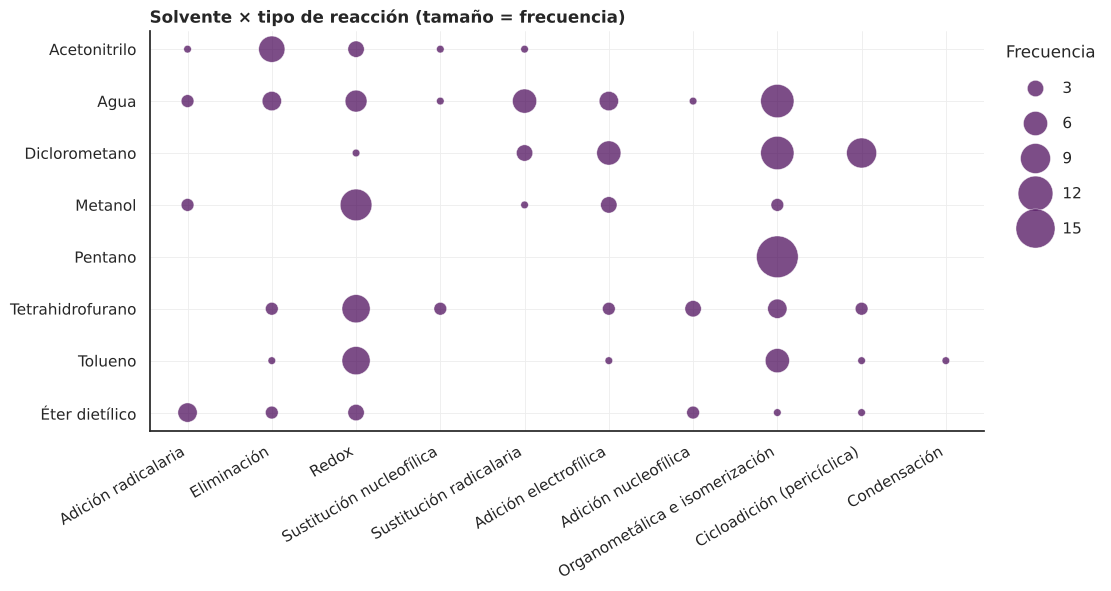

     Solvente               Tipo de reacción  n
      Pentano Organometálica e isomerización 17
Diclorometano Organometálica e isomerización 11
         Agua Organometálica e isomerización 11
      Metanol                          Redox 10
Diclorometano     Cicloadición (pericíclica)  9
Total de solventes distintos: 43


In [ ]:
# Relación química: qué solvente se usa con cada tipo de reacción (polaridad del solvente vs. mecanismo).
# Hay muchos solventes, así que se toman los 8 más frecuentes; el tamaño de la burbuja = frecuencia
# (la burbuja más grande es la combinación más probable).
filas = [rea, obt]
largo = pd.concat([d.melt(id_vars=['ID', 'Tipo de reacción'], value_vars=[c for c in d if c.startswith('Solvente')],
                          value_name='Solvente').dropna(subset=['Solvente']) for d in filas])
top = largo['Solvente'].value_counts().head(8).index        # 8 solventes más usados
t = largo[largo['Solvente'].isin(top)].groupby(['Solvente', 'Tipo de reacción']).size().reset_index(name='n')
fig, ax = plt.subplots(figsize=(11, 5.8), constrained_layout=True)
sns.scatterplot(data=t, x='Tipo de reacción', y='Solvente', size='n', sizes=(30, 900), color=COL_VAR['PM'],
                alpha=0.7, edgecolor='white', legend='brief', ax=ax)
ax.set_xlabel(''); ax.set_ylabel(''); ax.set_title('Solvente × tipo de reacción (tamaño = frecuencia)')
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
ax.legend(title='Frecuencia', bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False, labelspacing=1.3)
guardar(fig, '16_burbujas_solvente_tipo'); plt.show()
print(t.sort_values('n', ascending=False).head(5).to_string(index=False))
print('Total de solventes distintos:', largo['Solvente'].nunique())

**Tipo de gráfica.** Gráfico de burbujas en matriz: dos variables categóricas; el área de la burbuja es la frecuencia.

**Interpretación.** La burbuja mayor es el **pentano como solvente en reacciones organometálicas (17)**: los compuestos de litio y otros metales se manejan en disolventes apolares que no reaccionan con ellos. El diclorometano y el agua también aparecen sobre todo en lo organometálico (11 cada uno), el metanol en redox (10, hidrogenaciones) y el diclorometano en cicloadiciones (9).

### Gráfica 17. Cambio de peso molecular en las reacciones (ΔPM = producto − sustancia)

**Qué hace el código.**
- Para cada reacción, **ΔPM = PM del producto − PM del hidrocarburo** de partida (el PM del hidrocarburo se toma de la hoja Sustancias).
- Se dibuja un **diagrama de caja por hidrocarburo**, sin puntos encima, con una línea de referencia en 0.
- El eje y se limita a **1.2 × percentil 97** y el título dice cuántos valores quedan por fuera.
- Se imprimen **P(ΔPM > 0)** y la mediana de ΔPM por hidrocarburo.

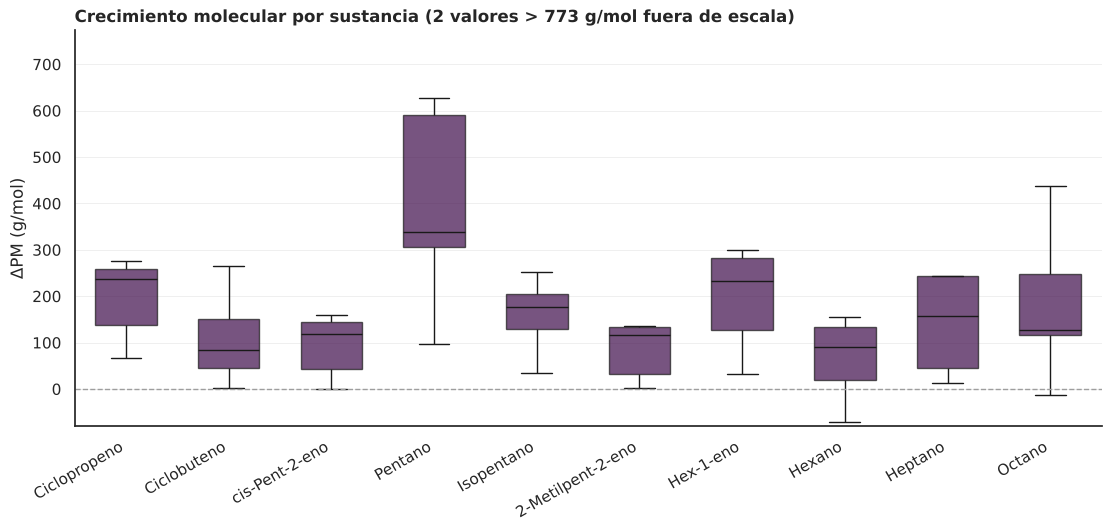

P(ΔPM > 0) = 0.93 de 97 reacciones
Sustancia
Ciclopropeno         237.0
Ciclobuteno           84.0
cis-Pent-2-eno       119.0
Pentano              339.0
Isopentano           176.0
2-Metilpent-2-eno    115.0
Hex-1-eno            233.0
Hexano                90.0
Heptano              158.0
Octano               127.0


In [ ]:
# Relación química: si la reacción añade átomos (adición, acoplamiento, acilación) el producto pesa más;
# si los quita (eliminación, reducción de grupos, ruptura) pesa menos. ΔPM > 0 = crecimiento molecular.
rx['ΔPM'] = rx['PM'] - rx['Sustancia'].map(sus.set_index('Sustancia')['PM'])
tope = rx['ΔPM'].quantile(0.97) * 1.2                      # escala: se recorta el 3 % más extremo
fig, ax = plt.subplots(figsize=(11, 5.2), constrained_layout=True)
sns.boxplot(data=rx, x='Sustancia', y='ΔPM', order=ORDEN, color=COL_VAR['PM'], fliersize=0, width=0.6,
            boxprops={'alpha': 0.7}, ax=ax)
ax.axhline(0, color=GRIS, ls='--', lw=1)                    # referencia: sin cambio de masa
ax.set_ylim(min(rx['ΔPM'].min() * 1.15, -50), tope); ax.set_xlabel(''); ax.set_ylabel('ΔPM (g/mol)')
fuera = int((rx['ΔPM'] > tope).sum())
ax.set_title(f'Crecimiento molecular por sustancia ({fuera} valores > {tope:.0f} g/mol fuera de escala)')
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
guardar(fig, '17_cambio_peso_molecular'); plt.show()
print(f"P(ΔPM > 0) = {(rx['ΔPM'] > 0).mean():.2f} de {rx['ΔPM'].notna().sum()} reacciones")
print(rx.groupby('Sustancia')['ΔPM'].median().reindex(ORDEN).round(0).to_string())

**Tipo de gráfica.** Diagrama de caja por sustancia, sin puntos encima.

**Interpretación.** En el 93 % de las reacciones (de 97) el producto pesa más que el hidrocarburo de partida: se le unen grupos funcionales o fragmentos completos. El pentano tiene la mediana más alta (+339 g/mol), porque en sus acoplamientos se une a moléculas grandes; el ciclobuteno (+84) y el hexano (+90) las más bajas, porque en muchas de sus reacciones solo se agregan unos pocos átomos (hidrogenación, oxidación, bromación).

### Gráficas 18 y 19. Interactivas (Plotly)

**Qué hace el código.**
- **Dispersión con plotly:** PM frente a Peb de los productos, con un color por mecanismo. Al pasar el cursor se ven el producto, el hidrocarburo, el ID y el medio.
- **Diagrama solar:** jerarquía de tres niveles, **hidrocarburo → medio → mecanismo**. Las reacciones sin medio aparecen como "Sin dato".
- Ambas figuras se exportan a **HTML**, que conserva la interactividad al abrirlo en el navegador.

In [ ]:
# Relación química: la misma tendencia PM–Peb, pero al pasar el cursor se ve el producto y la reacción.
d = rx.dropna(subset=['PM', 'Peb']).copy()
fig = px.scatter(d, x='PM', y='Peb', color='Tipo de reacción', hover_data=['Producto', 'Sustancia', 'ID', 'Medio'],
                 labels={'PM': UNIDAD['PM'], 'Peb': UNIDAD['Peb']}, height=550,
                 title='Productos: PM frente a Peb (pasa el cursor sobre los puntos)',
                 color_discrete_sequence=list(COL_VAR.values()))
fig.write_html(f'{CARPETA}/18_interactivo_PM_Peb.html'); fig.show()

# Gráfica solar: se lee del centro hacia afuera: sustancia → medio → tipo de reacción.
fig2 = px.sunburst(rx.fillna({'Medio': 'Sin dato'}), path=['Sustancia', 'Medio', 'Tipo de reacción'], height=600,
                   title='Sustancia → medio → tipo de reacción', color_discrete_sequence=list(COL_VAR.values()))
fig2.write_html(f'{CARPETA}/19_interactivo_solar.html'); fig2.show()

**Tipo de gráfica.** Dispersión interactiva y diagrama solar.

**Interpretación.** **Dispersión:** la misma relación PM–Peb, pero cada punto muestra su producto, su sustancia, su ID y su medio al pasar el cursor; cada color es un tipo de reacción y se puede ocultar desde la leyenda. **Diagrama solar:** del centro hacia afuera, sustancia → medio → tipo de reacción.

## 4. Descarga de las figuras

**Qué hace el código.** Se comprime la carpeta de figuras en un **.zip** (shutil.make_archive) y, en Colab, se descarga automáticamente (files.download). Son las mismas imágenes que se insertan en el informe de LaTeX.

In [ ]:
# Comprime la carpeta de figuras en un .zip y lo descarga (las figuras van al informe en LaTeX).
shutil.make_archive(CARPETA, 'zip', CARPETA)      # crea figuras_hidrocarburos.zip
if EN_COLAB:                                      # if: la descarga automática solo existe en Colab
    files.download(f'{CARPETA}.zip')
print('Figuras guardadas en', CARPETA)

Figuras guardadas en figuras_hidrocarburos
